In [9]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import urllib.request

from zipfile import ZipFile
from urllib.request import urlretrieve


from IPython.display import Image

%matplotlib inline

In [2]:
url = "https://api.worldbank.org/v2/en/indicator/NY.GDP.MKTP.CD?downloadformat=csv"

filename = "gdp_data.zip"
urllib.request.urlretrieve(url, filename)
## you are storing in the current directory only

('gdp_data.zip', <http.client.HTTPMessage at 0x1b55270b6b0>)


1. path.home() / "Downloads" / "names.zip"

This line targets a file inside the user's personal Downloads folder, no matter whose computer the script runs on.
* Path.home() (usually written with a capital P as Path.home()): Finds the current logged-in user's home directory.
	* Windows: C:\Users\YourName
	* Mac/Linux: /Users/YourName or /home/YourName
* / "Downloads": Moves inside the standard system "Downloads" folder.
* / "names.zip": Targets a file named names.zip inside that folder.
Final Result Example: C:\Users\YourName\Downloads\names.zip

2. Path(__file__).parent / "downloads" / "data.zip"

This line creates a path relative to the location of the script itself, making your code completely portable.
* __file__: A special Python variable that holds the full path to the current running .py script file.
* Path(__file__).parent: Grabs the folder where that script is living.
* / "downloads": Targets a subfolder named downloads inside the script's folder.
* / "data.zip": Targets a file named data.zip inside that subfolder.
Final Result Example: If your script is saved in D:\Projects\Bot\script.py, this resolves to D:\Projects\Bot\downloads\data.zip.



### Comparison Summary

| Path Expression | Target Location | Best Used For |
| :--- | :--- | :--- |
| **`Path.home() / ...`** | User's system folder (e.g., Desktop, Downloads) | Saving files where the user expects to find them easily. |
| **`Path(__file__).parent / ...`** | Internal project folders next to the code | Storing project assets, internal data, or local application settings. |


In [13]:
# using pathlib to store at particular location

import urllib.request

from pathlib import Path

# User Downloads folder

url = "https://api.worldbank.org/v2/en/indicator/NY.GDP.MKTP.CD?downloadformat=csv"

downloads_path = Path.home()/"Downloads"/"name.zip"

urllib.request.urlretrieve(url, downloads_path)


(WindowsPath('C:/Users/Prasad/Downloads/name.zip'),
 <http.client.HTTPMessage at 0x28714f2d6a0>)


The Clean Alternative: pathlib

Chaining ../../.. can quickly become confusing and hard to read. Python's modern pathlib library lets you use the .parent property instead, which is much cleaner:
python
from pathlib import Path

# Get the directory of the current script
current_dir = Path(__file__).resolve().parent

# Go up 2 levels
grandparent_dir = current_dir.parent.parent

# Open the file
file_path = grandparent_dir / "documents_file.txt"


In [15]:
## for a particular project directory
## will create a directory as a download in it and in that it will save

project_path = Path(__file__).parent/"downloads"/"data.zip"

urllib.request.urlretrieve(url, project_path)



NameError: name '__file__' is not defined

### 🚨 Why the Error Happened: `NameError: name '__file__' is not defined`

In traditional Python scripts (`.py` files), the special variable `__file__` contains the file path of the script currently being executed. 

However, **Jupyter Notebooks run interactively** inside a web browser session rather than executing a standard script from disk. Because the code is executed in blocks (cells) through an interactive kernel, **`__file__` does not exist in the Jupyter environment**, leading to the `NameError`.

---

### 🛠️ How the Fix Works: Using `Path.cwd()`

To replicate the behavior of `__file__` inside a Jupyter Notebook, we switch to `Path.cwd()` from Python's built-in `pathlib` library.

1. **`Path.cwd()` (Current Working Directory):** This function dynamically looks up the absolute path of the folder where your active notebook (`.ipynb`) is located.
2. **Directory Creation (`.mkdir`):** Jupyter won't automatically create folders if they don't exist yet. Adding `.mkdir(parents=True, exist_ok=True)` ensures Python creates the `downloads` folder safely before downloading the file, preventing a `FileNotFoundError`.


In [3]:
## Download the assets



def download_and_unzip(url, save_path):
    print("Downloading\n")

    urlretrieve(url, save_path)

    try:
        with ZipFile(save_path) as z:
            z.extractall(os.path.split(save_path)[0])
        print('Done')

    except Exception as e:
        print("\nInvalid file.", e)
    

In [4]:
URL = r"https://www.dropbox.com/s/qhhlqcica1nvtaw/opencv_bootcamp_assets_NB1.zip?dl=1"
asset_zip_path = os.path.join(os.getcwd(), f"opencv_bootcamp_assets_NB1.zip")

# Download if asset ZIP does not exists

if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

In [5]:
# Display image 18 by 18 pixel

Image(filename="checkerboard_18x18.png")

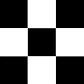

In [6]:
# Display 84 by 84 image

Image(filename= "checkerboard_84x84.jpg")

## Reading images using OpenCV
OpenCV allows reading different types of images (JPG, PNG, etc). You can load grayscale images, color images or you can also load images with Alpha channel. It uses the cv2.imread() function which has the following syntax:

Function Syntax
retval = cv2.imread( filename[, flags] )
retval: Is the image if it is successfully loaded. Otherwise it is None. This may happen if the filename is wrong or the file is corrupt.

The function has 1 required input argument and one optional flag:

1. filename: This can be an absolute or relative path. This is a mandatory argument.

2. Flags: These flags are used to read an image in a particular format (for example, grayscale/color/with alpha channel). This is an optional argument with a default value of cv2.IMREAD_COLOR or 1 which loads the image as a color image.

Before we proceed with some examples, let's also have a look at some of the flags available.

Flags

1. cv2.IMREAD_GRAYSCALE or 0: Loads image in grayscale mode
2. cv2.IMREAD_COLOR or 1: Loads a color image. Any transparency of image will be neglected. It is the default flag.
3. cv2.IMREAD_UNCHANGED or -1: Loads image as such including alpha channel.


In [7]:
# Read image as gray scale.
cb_img = cv2.imread("checkerboard_18x18.png", 0)



# Print the image data pixel data (pixel, values), element of a 2D numpy array.
# Each pixel value is 8-bits (0, 255)
print(cb_img)

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

In [23]:
## display some information related to image

# print the size of image

print("Image size (H, W) is:", cb_img.shape)

# print data-tyoe of image
print("Data type of image is:", cb_img.dtype)

Image size (H, W) is: (18, 18)
Data type of image is: uint8


An image with a data type of uint8 stores pixel values as unsigned 8-bit integers, meaning the value of each pixel is restricted to a strict whole-number range of 0 to 255.

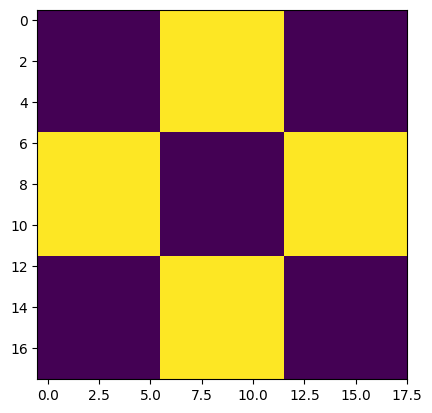

In [25]:
# display using matplotlib
plt.imshow(cb_img)
plt.show()

# What happened?
Even though the image was read in as a gray scale image, it won't necessarily display in gray scale when using imshow(). matplotlib uses different color maps and it's possible that the gray scale color map is not set.



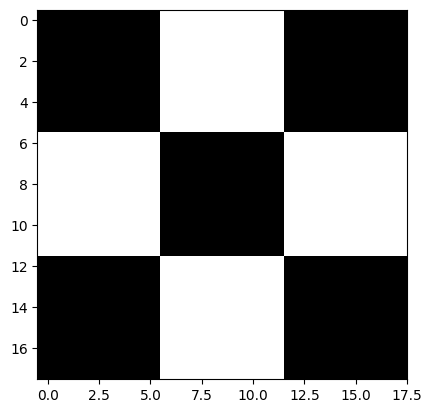

In [28]:
# set color map to gray scale for proper rendering.

plt.imshow(cb_img, cmap='gray')
plt.show()

[[  0   0  15  20   1 134 233 253 253 253 255 229 130   1  29   2   0   0]
 [  0   1   5  18   0 137 232 255 254 247 255 228 129   0  24   2   0   0]
 [  7   5   2  28   2 139 230 254 255 249 255 226 128   0  27   3   2   2]
 [ 25  27  28  38   0 129 236 255 253 249 251 227 129   0  36  27  27  27]
 [  2   0   0   4   2 130 239 254 254 254 255 230 126   0   4   2   0   0]
 [132 129 131 124 121 163 211 226 227 225 226 203 164 125 125 129 131 131]
 [234 227 230 229 232 205 151 115 125 124 117 156 205 232 229 225 228 228]
 [254 255 255 251 255 222 102   1   0   0   0 120 225 255 254 255 255 255]
 [254 255 254 255 253 225 104   0  50  46   0 120 233 254 247 253 251 253]
 [252 250 250 253 254 223 105   2  45  50   0 127 223 255 251 255 251 253]
 [254 255 255 252 255 226 104   0   1   1   0 120 229 255 255 254 255 255]
 [233 235 231 233 234 207 142 106 108 102 108 146 207 235 237 232 231 231]
 [132 132 131 132 130 175 207 223 224 224 224 210 165 134 130 136 134 134]
 [  1   1   3   0   0 129

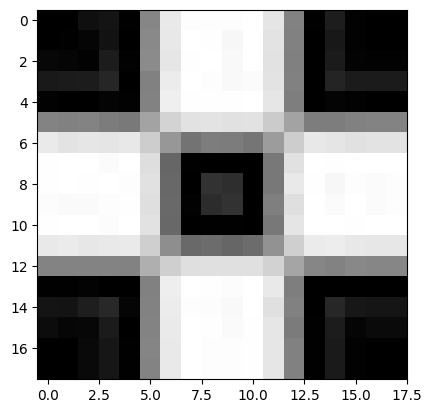

In [31]:
# Read image as gray scale
cb_img_fuzzy = cv2.imread("checkerboard_fuzzy_18x18.jpg", 0)


# print image
print(cb_img_fuzzy)

# Display image.

plt.imshow(cb_img_fuzzy, cmap = "gray")
plt.show()

# color image using Ipython Image function

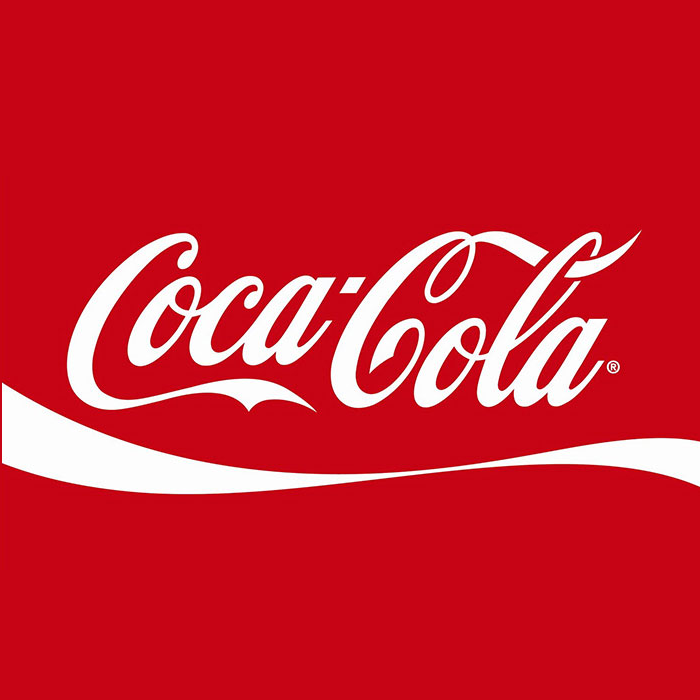

In [33]:
# Color image

Image('coca-cola-logo.png')

## Now using opencv to read a color image 

In [34]:
# Read in the image
coke_img = cv2.imread("coca-cola-logo.png")

# print the size of image
print("Image size is ", coke_img.shape)


#print data-type of image
print("Data type of image is ", coke_img.dtype)

print("")


Image size is  (700, 700, 3)
Data type of image is  uint8



# display the image


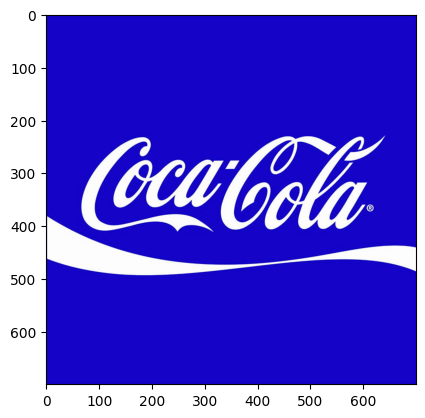

In [36]:
plt.imshow(coke_img)
plt.show()

The color displayed above is different from the actual image. This is because matplotlib expects the image in RGB format whereas OpenCV stores images in BGR format. Thus, for correct display, we need to reverse the channels of the image. We will discuss about the channels in the sections below.



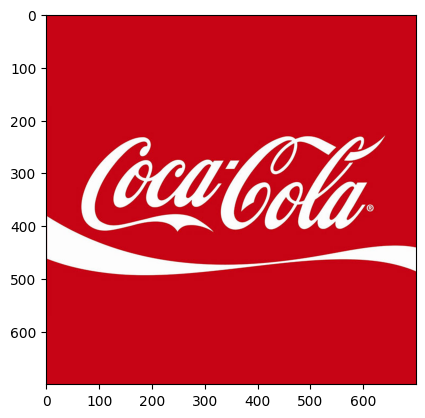

In [38]:
coke_img_channels_reversed = coke_img[:, :, ::-1]
plt.imshow(coke_img_channels_reversed)
plt.show()

# Splitting and Merging Color Channels
* __cv2.split()__ Divides a multi-channel array into several single-channel arrays.

* __cv2.merge()__ Merges several arrays to make a single multi-channel array. All the input matrices must have the same size

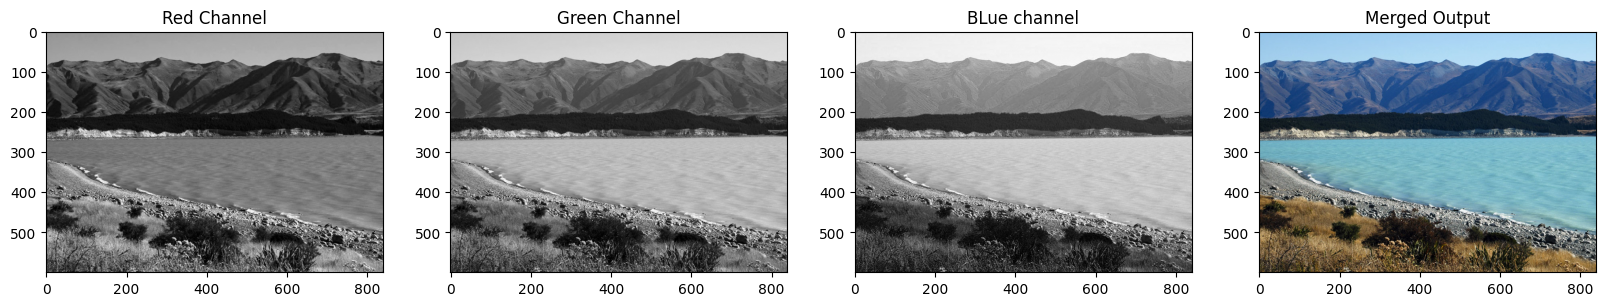

In [11]:
# split the image into the B, G R components
img_NZ_bgr = cv2.imread("New_Zealand_Lake.jpg", cv2.IMREAD_COLOR)
b, g, r = cv2.split(img_NZ_bgr)

# Show the channels
plt.figure(figsize = [20, 5])

plt.subplot(141);plt.imshow(r, cmap="gray");plt.title("Red Channel")
plt.subplot(142);plt.imshow(g, cmap="gray");plt.title("Green Channel")
plt.subplot(143);plt.imshow(b, cmap='gray');plt.title("BLue channel")


# Merge the individual channels into a BGR image
imgMerged = cv2.merge((b,g,r))

# Show the merged  output
plt.subplot(144)
plt.imshow(imgMerged[:,:,::-1])
plt.title("Merged Output")


plt.show()

In the plt.imshow() function, r, g, and b represent 2D grids of pixel intensity values (matrices) extracted from your image.
Here is exactly what happens when you pass them into plt.imshow(variable, cmap="gray"):

1. They act as "Brightness Maps"

Because you isolated the channels, r, g, and b are no longer seen by Matplotlib as "colors." Instead, each one is just a single layer of numbers (typically ranging from 0 to 255).
* Higher numbers (closer to 255): Represent areas where that specific color was very strong or bright in the original image.
* Lower numbers (closer to 0): Represent areas where that specific color was weak or completely absent (dark).

2. The role of cmap="gray"

Because a single 2D channel has no built-in color information, Matplotlib needs a Color Map (cmap) to know how to display those numbers.
* By setting cmap="gray", you tell Matplotlib to map 0 to Black and 255 to White.
* For example, in the Red Channel plot, any object that was bright red in real life will appear bright white, while objects with no red at all will appear pitch black.

Summary of what you see on screen:

* plt.imshow(r, cmap="gray") shows you where and how much Red light exists in the image.

* plt.imshow(g, cmap="gray") shows you where and how much Green light exists.
* plt.imshow(b, cmap="gray") shows you where and how much Blue light exists.

# Converting to different Color Spaces
__cv2.cvtColor()__ Converts an image from one color space to another. The function converts an input image from one color space to another. In case of a transformation to-from RGB color space, the order of the channels should be specified explicitly (RGB or BGR). Note that the default color format in OpenCV is often referred to as RGB but it is actually BGR (the bytes are reversed). So the first byte in a standard (24-bit) color image will be an 8-bit Blue component, the second byte will be Green, and the third byte will be Red. The fourth, fifth, and sixth bytes would then be the second pixel (Blue, then Green, then Red), and so on.

# Converting to different Color Spaces
__cv2.cvtColor()__ Converts an image from one color space to another. The function converts an input image from one color space to another. In case of a transformation to-from RGB color space, the order of the channels should be specified explicitly (RGB or BGR). Note that the default color format in OpenCV is often referred to as RGB but it is actually BGR (the bytes are reversed). So the first byte in a standard (24-bit) color image will be an 8-bit Blue component, the second byte will be Green, and the third byte will be Red. The fourth, fifth, and sixth bytes would then be the second pixel (Blue, then Green, then Red), and so on.

__Function Syntax__
dst = cv2.cvtColor( src, code )

dst: Is the output image of the same size and depth as src.

The function has 2 required arguments:

1. src input image: 8-bit unsigned, 16-bit unsigned ( CV_16UC... ), or single-precision floating-point.

2. code color space conversion code (see ColorConversionCodes).



# Changing from BGR to RGB

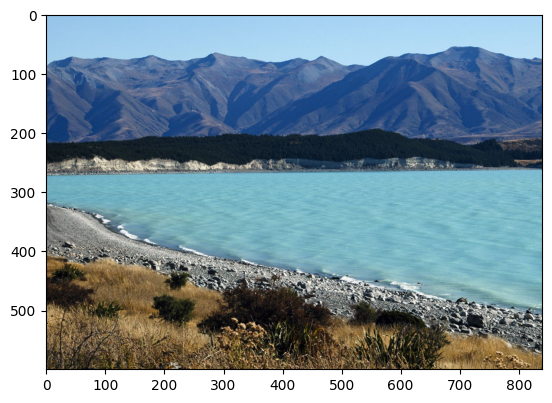

In [12]:
# opencv stores color channels in a different order than most other applications (BGR vs RGB)
img_NZ_rgb = cv2.cvtColor(img_NZ_bgr, cv2.COLOR_BGR2RGB)
plt.imshow(img_NZ_rgb)
plt.show()

# changing to hsv color space


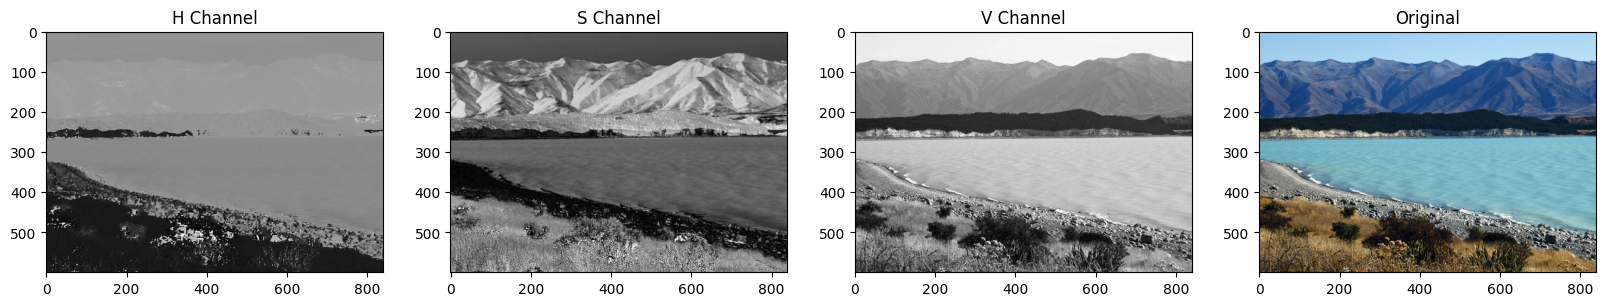

In [15]:
img_hsv = cv2.cvtColor(img_NZ_bgr, cv2.COLOR_BGR2HSV)

# Split the image into the B,G,R components
h, s, v = cv2.split(img_hsv)

# Show the channels
plt.figure(figsize=[20,5])
plt.subplot(141);plt.imshow(h, cmap="gray");plt.title("H Channel");
plt.subplot(142);plt.imshow(s, cmap="gray");plt.title("S Channel");
plt.subplot(143);plt.imshow(v, cmap="gray");plt.title("V Channel");
plt.subplot(144);plt.imshow(img_NZ_rgb); plt.title("Original");

plt.show()


1. plt.imshow(h, cmap="gray") — Hue (The Color Type)

Hue represents the actual color type on a 360-degree color wheel (like Red, Yellow, Green, Cyan, Blue, Magenta). However, 8-bit images can only store numbers up to 255, so OpenCV divides the wheel degrees by 2. Hue values range from 0 to 179.
* 🟥 Dark / Near Black (Values near 0 or 179): Represents Red colors.
* 🟩 Medium Gray (Values around 30 to 60): Represents Greens.
* 🟦 Light Gray / White (Values around 100 to 130): Represents Blues.
* Note: The brightness here does not mean "bright color"—it simply tells you where that color falls on the color wheel.

2. plt.imshow(s, cmap="gray") — Saturation (The Color Purity)

Saturation measures how vivid, intense, or pure a color is. Values range from 0 to 255.
* ⚪ Bright White (Values near 255): The color is highly saturated, rich, and vibrant (like a bright red apple or neon sign).
* ⚫ Pure Black (Value = 0): The color is completely faded—it has no color pigment at all (grayscale, white, black, or gray tones).

3. plt.imshow(v, cmap="gray") — Value (The Brightness)

Value measures the luminous intensity, or how much light is reflecting off the object. Values range from 0 to 255.
* ⚪ Bright White: The area is highly illuminated, light, or reflective (like sunlight hitting a surface or a white wall).
* ⚫ Pure Black: The area is in complete shadow, dark, or pitch black, regardless of what color it actually is.

# Modifying individual channel

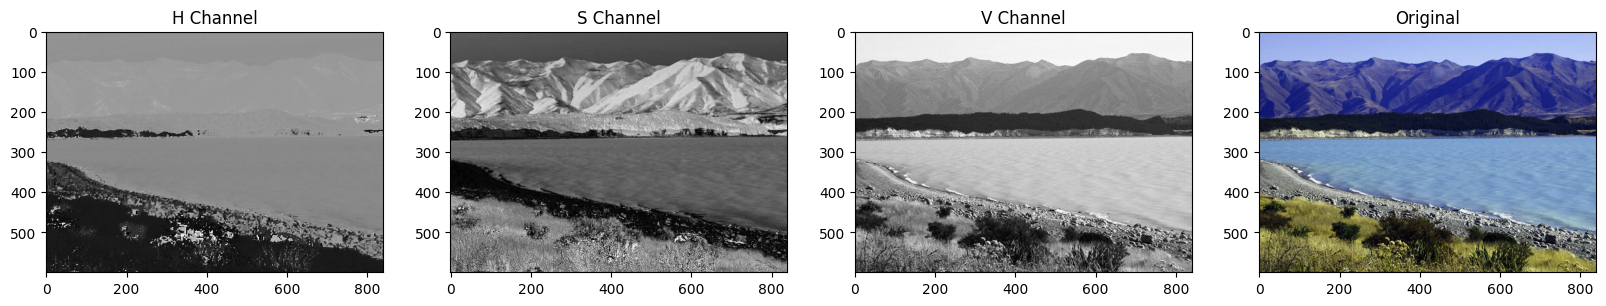

In [19]:
h_new = h + 10
img_NZ_merged = cv2.merge((h_new, s, v))
img_NZ_rgb = cv2.cvtColor(img_NZ_merged, cv2.COLOR_HSV2RGB)


# Show the channels
plt.figure(figsize=[20,5])
plt.subplot(141);plt.imshow(h, cmap="gray");plt.title("H Channel");
plt.subplot(142);plt.imshow(s, cmap="gray");plt.title("S Channel");
plt.subplot(143);plt.imshow(v, cmap="gray");plt.title("V Channel");
plt.subplot(144);plt.imshow(img_NZ_rgb); plt.title("Original");

plt.show()

# Saving Images
Saving the image is as trivial as reading an image in OpenCV. We use the function __cv2.imwrite()__ with two arguments. The first one is the filename, second argument is the image object.

The function imwrite saves the image to the specified file. The image format is chosen based on the filename extension (see cv::imread for the list of extensions). In general, only 8-bit single-channel or 3-channel (with 'BGR' channel order) images can be saved using this function (see the OpenCV documentation for further details).

__Function Syntax__

cv2.imwrite( filename, img[, params] )
The function has 2 required arguments:

1. filename: This can be an absolute or relative path.

2. img: Image or Images to be saved.

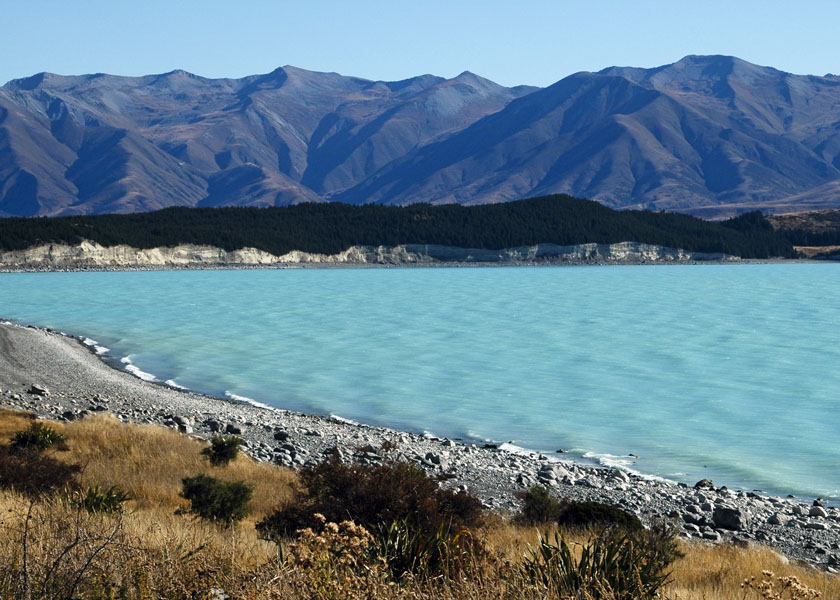

In [20]:
# save the image
cv2.imwrite("New_Zealand_Lake_SAVED.png", img_NZ_bgr)

Image(filename='New_Zealand_Lake_SAVED.png')

__If the filename you pass to cv2.imwrite() already exists, OpenCV will overwrite the old file entirely without warning.__

In [21]:
# read the image as Color
img_NZ_bgr = cv2.imread("New_Zealand_Lake_SAVED.png", cv2.IMREAD_COLOR)
print("img_NZ_bgr shape (H, W, C) is:", img_NZ_bgr.shape)


# read the image as Grayscaled
img_NZ_gry = cv2.imread("New_Zealand_Lake_SAVED.png", cv2.IMREAD_GRAYSCALE)
print("img_NZ_gry shape (H, W) is:", img_NZ_gry.shape)

img_NZ_bgr shape (H, W, C) is: (600, 840, 3)
img_NZ_gry shape (H, W) is: (600, 840)


__u cannot use cv2.imshow() directly in a Jupyter Notebook safely, because it creates a separate native GUI window that often freezes, hangs the background process, or causes the entire Jupyter kernel to crash__